# GSB 5544 — Topic 9.1: K-Nearest Neighbors and Decision Trees for Regression — SOLUTION
*Three algorithms, one scikit-learn recipe. Watch each algorithm on the animation page, then reproduce what it did in pandas and scikit-learn.*

## The next 20 minutes

Last week the model was a line. This week two models make predictions in a different way: by **averaging
the nearest training rows** (k-nearest neighbors) and by **asking yes/no questions** (a decision tree).
The code barely changes; the idea behind the prediction does.

| | | tools |
|---|---|---|
| **1. One tiny data set** | eight houses: size → price, plus one new house | `pd.DataFrame`, `plot.scatter` |
| **2. Linear regression in motion** | the fitted line, the residuals, a prediction | `LinearRegression`, `.fit`, `.predict` |
| **3. KNN in motion** | the k nearest houses, their average, the staircase | `KNeighborsRegressor(n_neighbors=k)` |
| **4. Decision tree in motion** | score every split, keep the best, repeat, follow the questions | `DecisionTreeRegressor(max_depth=d)`, `plot_tree` |
| **5. Same recipe** | what changes between the three, what does not | `train_test_split`, `root_mean_squared_error` |
| **6. Definition: Pipeline** | preprocessing + model as one object | `Pipeline`, `ColumnTransformer`, `OneHotEncoder`, `StandardScaler` |
| **7. Review questions** | short checks on the animations and the workflow | |

🎬 **The animation page:** [https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html](https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html). It uses the same eight houses as this notebook, computes
everything in the browser, and highlights the line of scikit-learn code behind each step. Each algorithm has
its own address (`#linear-regression`, `#knn`, `#decision-tree`); the 🎬 links below open the page there.

**Rhythm for each section:** open the 🎬 link and watch → *predict* the number the notebook is about to print →
run the cell → compare with the page.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree

---
## 1. One tiny data set

Eight houses. **Size** is in hundreds of square feet, **price** in thousands of dollars. Small enough to
check every number by hand — which is the point. As in Topic 8.2, `X` is a DataFrame (double brackets) and
`y` is a Series.

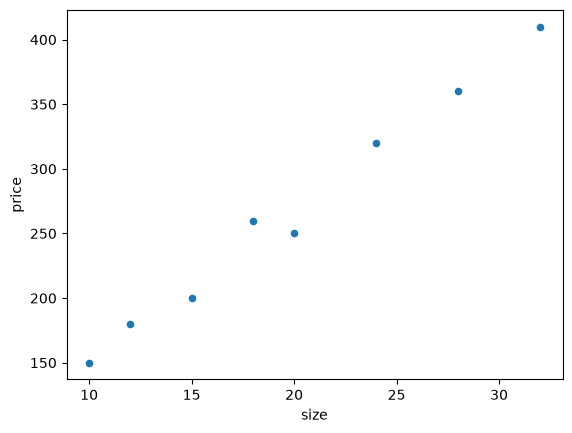

In [2]:
houses = pd.DataFrame({
    "size":  [10, 12, 15, 18, 20, 24, 28, 32],         # hundreds of square feet
    "price": [150, 180, 200, 260, 250, 320, 360, 410], # thousands of dollars
})
X = houses[["size"]]
y = houses["price"]
houses.plot.scatter(x="size", y="price");

And one **new house** of size 22.5 (2,250 square feet) whose price we want to predict. Every algorithm below
will be asked the same question about it. `predict` wants a DataFrame with the same column name as `X`.

In [3]:
new = pd.DataFrame({"size": [22.5]})
new

,size
0,22.5


---
## 2. Linear regression in motion

The model is a line, price ≈ intercept + slope × size. The animation shows the three things `fit` and
`predict` do: pick the line with the **smallest sum of squared residuals**, measure each **residual**
(actual − predicted, the vertical gap from a point to the line), and read a new size **off the line**.

🎬 *Watch it on the page:* [Linear regression: one line, chosen by least squares](https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html#linear-regression) — press **Play**, or step through with → and ←.

In [4]:
line = LinearRegression()
line.fit(X, y)
print("intercept:", round(line.intercept_, 2), "  slope:", line.coef_.round(3))

intercept: 33.29   slope: [11.721]


The residuals, one per house, and their sum of squares. Compare the table with the page's table after the
residual steps.

In [5]:
houses["predicted"] = line.predict(X)
houses["residual"]  = houses["price"] - houses["predicted"]
print("sum of squared residuals:", round((houses["residual"] ** 2).sum(), 2))
houses.round(2)

sum of squared residuals: 715.08


,size,price,predicted,residual
0,10,150,150.50,-0.50
1,12,180,173.95,6.05
2,15,200,209.11,-9.11
3,18,260,244.27,15.73
4,20,250,267.72,-17.72
5,24,320,314.60,5.40
6,28,360,361.48,-1.48
7,32,410,408.37,1.63


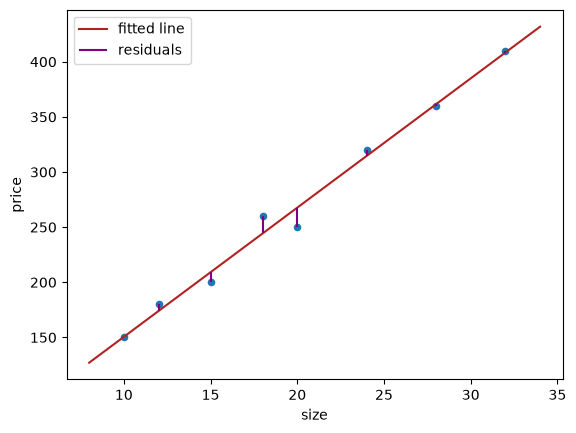

In [6]:
ax = houses.plot.scatter(x="size", y="price")
sizes = pd.DataFrame({"size": np.linspace(8, 34, 261)})
ax.plot(sizes["size"], line.predict(sizes), color="firebrick", label="fitted line")
ax.vlines(houses["size"], houses["predicted"], houses["price"], color="purple", label="residuals")
ax.legend();

In [7]:
line.predict(new)

array([297.017991])

✅ **Checkpoint 1.** (a) Read the slope in the data's units. (b) The residual for the size-20 house is about
−17.7: what does the minus sign say about that house? (c) Why can no other line have a smaller sum of squared
residuals than 715.1?

**Answer:** (a) Each extra hundred square feet is associated with about 11.7 thousand dollars more in price (≈ \$117 per
square foot). (b) That house sold for about 17.7 thousand dollars *less* than the line predicts for its size;
it sits below the line. (c) Because that is how the line was chosen: least squares searches over every
intercept and slope and keeps the pair with the smallest sum of squared residuals. Any other line scores
higher by definition. The prediction for the new house is 33.29 + 11.72 × 22.5 ≈ **297.0** thousand dollars.

---
## 3. K-nearest neighbors in motion

KNN does not fit a shape at all. To predict a new house it **measures the distance to every training house,
keeps the k closest, and averages their prices**. `fit` only stores the training rows. With one feature the
distance is just the gap along the size axis, so no scaling is needed; section 5 says what changes with more
features.

🎬 *Watch it on the page:* [K-nearest neighbors: ask the k most similar houses](https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html#knn) — press **Play**, or step through with → and ←.

First by hand, exactly as the animation does it: distance from every house to the new size, sort, keep three,
average.

In [8]:
houses["distance"] = (houses["size"] - 22.5).abs()
nearest = houses.sort_values("distance").head(3)
print("prediction by hand:", round(nearest["price"].mean(), 2))
nearest[["size", "price", "distance"]]

prediction by hand: 276.67


,size,price,distance
5,24,320,1.5
4,20,250,2.5
3,18,260,4.5


Then with scikit-learn. Same recipe as the line: create, fit, predict. Only the first line changed.

In [9]:
knn3 = KNeighborsRegressor(n_neighbors=3)
knn3.fit(X, y)
knn3.predict(new)

array([276.66666667])

**The regression function.** Ask for a prediction at every size between 8 and 34 and the shape appears: a
**staircase**. The prediction changes only when the set of k nearest houses changes. Three values of k on one
plot, as in the last step of the animation (and as PA 9.1 asks you to sketch for the wine data).

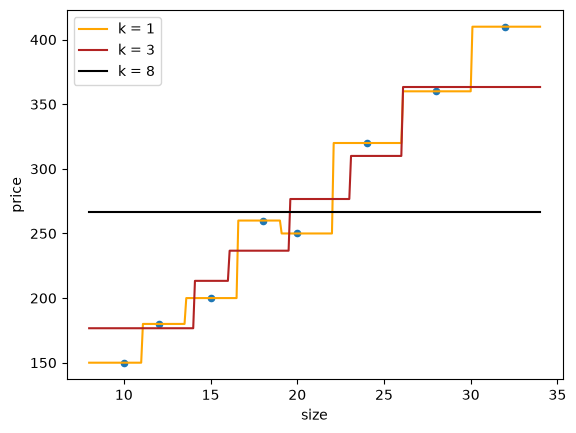

In [10]:
ax = houses.plot.scatter(x="size", y="price")
for k, color in zip([1, 3, 8], ["orange", "firebrick", "black"]):
    model = KNeighborsRegressor(n_neighbors=k).fit(X, y)
    ax.plot(sizes["size"], model.predict(sizes), color=color, label=f"k = {k}")
ax.legend();

✅ **Checkpoint 2.** (a) With k = 1, what is the prediction for size 22.5, and which house supplies it?
(b) Why is the k = 1 function a staircase rather than a line, and where exactly are its jumps? (c) Why is the
k = 8 function flat, and at what height?

**Answer:** (a) **320**: the nearest house is the size-24 one (distance 1.5), and with k = 1 the prediction *is* that
house's price. (b) Between two training sizes the nearest house does not change, so the prediction stays
constant; it jumps at the **midpoints** between consecutive sizes (11, 13.5, 16.5, 19, 22, 26, 30), where the
nearest house switches. (c) There are only 8 houses, so with k = 8 every size has the same 8 neighbors and the
prediction is always their mean, **266.25**. (For k = 3 the prediction at 22.5 is (320 + 250 + 260) / 3 =
276.67, from the houses of size 24, 20 and 18.)

---
## 4. Decision tree in motion

A tree predicts by asking **yes/no questions** about the features: "size ≤ 22?" Fitting means finding the
best question. For one numeric feature the candidate thresholds are the midpoints between neighboring sizes;
each candidate splits the houses into two groups, and its score is the **sum of squared errors (SSE)** of the
prices around the two group means. The smallest SSE wins. Then the same search runs again inside each group,
until `max_depth` levels of questions have been asked.

🎬 *Watch it on the page:* [Decision tree: split, then split again](https://gato365.github.io/gsb5544_instructor_learn_prep/week_9/algorithms.html#decision-tree) — press **Play**, or step through with → and ←.

The root split by hand: every candidate threshold and its SSE. (`sse` is the squared distance of each group's
prices from the group's own mean.)

In [11]:
def sse(prices):
    return ((prices - prices.mean()) ** 2).sum()

sorted_sizes = sorted(houses["size"])
candidates = [(a + b) / 2 for a, b in zip(sorted_sizes[:-1], sorted_sizes[1:])]

rows = []
for t in candidates:
    left  = houses[houses["size"] <= t]["price"]
    right = houses[houses["size"] > t]["price"]
    rows.append({"threshold": t, "left_mean": left.mean(), "right_mean": right.mean(),
                 "SSE": sse(left) + sse(right)})
pd.DataFrame(rows).round(1)

,threshold,left_mean,right_mean,SSE
0,11.0,150.0,282.9,42542.9
1,13.5,165.0,300.0,30650.0
2,16.5,176.7,320.0,19466.7
3,19.0,197.5,335.0,20175.0
4,22.0,208.0,363.3,12746.7
5,26.0,226.7,385.0,20383.3
6,30.0,245.7,410.0,34371.4


scikit-learn agrees. `max_depth=1` is a single question; `plot_tree` draws it with the SSE (shown as
`squared_error`, the mean per house), the number of houses and the mean price in each node.

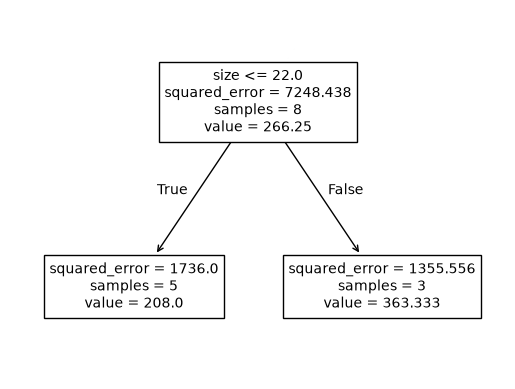

In [12]:
stump = DecisionTreeRegressor(max_depth=1).fit(X, y)
plot_tree(stump, feature_names=["size"], fontsize=10);

Two levels of questions. Follow the new house down: is 22.5 ≤ 22? No, go right. Is 22.5 ≤ 30? Yes, go left.
The leaf's mean price is the prediction.

array([340.])

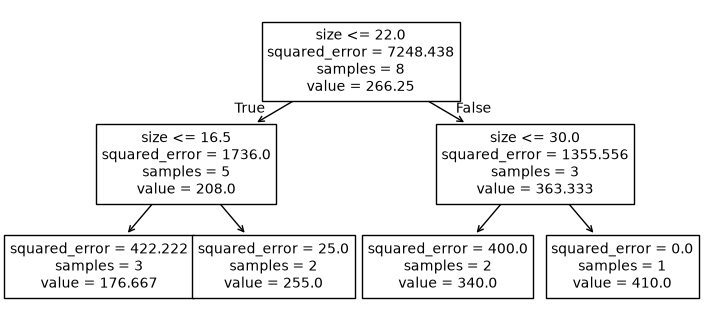

In [13]:
tree2 = DecisionTreeRegressor(max_depth=2).fit(X, y)
plt.figure(figsize=(9, 4))
plot_tree(tree2, feature_names=["size"], fontsize=10)
tree2.predict(new)

The regression function is again a staircase: **one flat value per leaf**. More depth means more leaves and
finer steps; at depth 3 every house but one gets its own leaf.

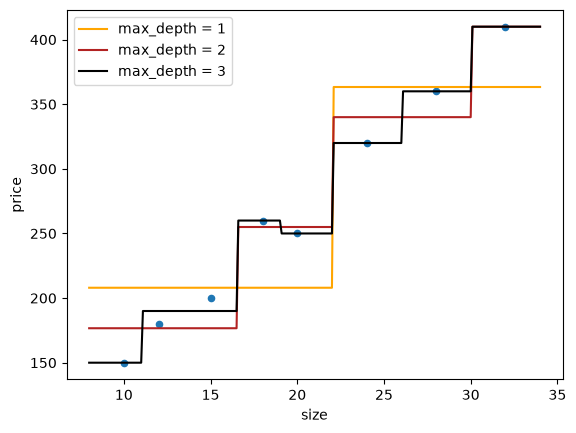

In [14]:
ax = houses.plot.scatter(x="size", y="price")
for depth, color in zip([1, 2, 3], ["orange", "firebrick", "black"]):
    model = DecisionTreeRegressor(max_depth=depth).fit(X, y)
    ax.plot(sizes["size"], model.predict(sizes), color=color, label=f"max_depth = {depth}")
ax.legend();

✅ **Checkpoint 3.** (a) Which threshold wins at the root, and which number decides it? (b) What does the
depth-2 tree predict for the new house, and which two questions did it answer on the way? (c) What happens to
the staircase as `max_depth` grows, and what word from Topic 8.2 describes a tree that is too deep?

**Answer:** (a) **size ≤ 22**, because its SSE (12,747) is the smallest of the seven candidates; the runner-up, 16.5, scores
19,467. (b) **340**: 22.5 ≤ 22 is false (go right), 22.5 ≤ 30 is true (go left), and that leaf holds the
size-24 and size-28 houses, mean (320 + 360) / 2 = 340. (c) The steps get narrower and more numerous until
each leaf holds a single house and the function passes through every training point; the training error is
then zero, which is **overfitting** — the depth is a hyperparameter to be chosen on test data, just like the
polynomial degree last week.

---
## 5. Same recipe, different model

Everything you learned with `LinearRegression` carries over unchanged: **define `X` and `y` → split → create
the model → `.fit()` → `.predict()` → evaluate**. Read the three columns; only the shaded rows differ.

| step | linear regression | k-nearest neighbors | decision tree |
|---|---|---|---|
| import | `LinearRegression` | `KNeighborsRegressor` | `DecisionTreeRegressor` |
| define `X`, `y` | same | same | same |
| split | `train_test_split(...)` | same | same |
| **create** | `LinearRegression()` — no hyperparameters | `KNeighborsRegressor(n_neighbors=k)` | `DecisionTreeRegressor(max_depth=d)` |
| fit | `.fit(X_train, y_train)` | same | same |
| **what `.fit` learns** | intercept and slope | nothing: stores the rows | thresholds and leaf means |
| predict | `.predict(X_test)` | same | same |
| evaluate | `root_mean_squared_error(y_test, pred)` | same | same |
| **scale numeric features?** | not needed | **yes**, with more than one feature | not needed |
| categorical features | one-hot encode | one-hot encode | one-hot encode |
| **shape of the prediction** | line | staircase of local averages | staircase, one value per leaf |

**Why scaling matters only for KNN.** KNN measures distance, and a feature in square feet (hundreds to
thousands) would drown out a feature in bedrooms (1 to 5). `StandardScaler` puts every feature on the same
footing. A tree asks each question about one feature at a time, so the units of other features never
interfere; a linear model absorbs units into its coefficients. All three need categorical features turned
into numbers first (`OneHotEncoder`).

The Advertising data from Topic 8.2, three models, one loop. The pipeline around KNN is the subject of
section 6; for now, notice that the loop body is *identical* for all three.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

ads = pd.read_csv("https://www.statlearning.com/s/Advertising.csv", index_col=0)
X_ads = ads[["TV", "radio"]]
y_ads = ads["sales"]
X_train, X_test, y_train, y_test = train_test_split(X_ads, y_ads, test_size=0.25, random_state=5544)

models = {
    "linear regression":   LinearRegression(),
    "3-nearest neighbors": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=3)),
    "tree, max_depth=4":   DecisionTreeRegressor(max_depth=4, random_state=5544),
}
for name, model in models.items():
    model.fit(X_train, y_train)
    rmse_train = root_mean_squared_error(y_train, model.predict(X_train))
    rmse_test  = root_mean_squared_error(y_test, model.predict(X_test))
    print(f"{name:20s}  train RMSE = {rmse_train:.2f}   test RMSE = {rmse_test:.2f}")

linear regression     train RMSE = 1.69   test RMSE = 1.62
3-nearest neighbors   train RMSE = 0.63   test RMSE = 0.90
tree, max_depth=4     train RMSE = 1.02   test RMSE = 1.82


✅ **Checkpoint 4.** (a) Which lines inside the loop would change if you added a fourth model? (b) Which model
predicts the test markets best here, and what is it about the data that a line cannot capture? (c) Why is the
tree's training RMSE so much better than its test RMSE compared with the line?

**Answer:** (a) None. Only the dictionary entry changes: a new import and a new `Model(...)` call with its hyperparameters.
`fit`, `predict` and the error calculation are the same three lines for every scikit-learn model. (b) The
**3-nearest-neighbor** model (test RMSE ≈ 0.90 versus 1.62 for the line and 1.82 for the tree). Sales rise
faster when TV *and* radio are both high — the TV × radio interaction from Topic 8.2 — and a flat line in TV
and radio cannot bend that way; averaging nearby markets follows the curve automatically. (c) A tree with 16
leaves can carve the 150 training markets into boxes that fit them closely (train 1.02) but each box's single
value is a coarse prediction for new markets (test 1.82); the line is too simple to overfit, so its two errors
are nearly equal. As always, the **test** error decides.

---
## 6. Definition: Pipeline

> 📦 **Definition — Pipeline.** *(Editable: reword this box as you like.)*
> A scikit-learn **Pipeline combines preprocessing steps and a model into one ordered workflow** that behaves
> like a single model: it has `.fit()` and `.predict()`, and those are the only two calls you make.
>
> - `pipe.fit(X_train, y_train)` runs the steps in order. Each preprocessing step **learns what it needs from
>   the training data** (a scaler learns the mean and standard deviation; a one-hot encoder learns the list of
>   categories), transforms the data and passes it on; the model at the end is fitted on the transformed data.
> - `pipe.predict(X_new)` applies **the same fitted preprocessing** to the new observations — the *training*
>   mean and standard deviation, the *training* categories; nothing is re-learned from the new rows — and then
>   asks the model.
>
> A pipeline is **not a prediction algorithm**. It makes no predictions of its own; it organizes the steps so
> that the right preprocessing always travels with the model.

Give the houses a categorical feature and the recipe needs preprocessing: one-hot encode `garage`, scale
`size`, then KNN. `ColumnTransformer` says which step applies to which column; `Pipeline` chains the
transformer and the model. This is exactly the structure PA 9.1 uses for the Ames neighborhoods.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

houses["garage"] = ["no", "no", "yes", "no", "yes", "yes", "yes", "yes"]
X2 = houses[["size", "garage"]]

preprocessing = ColumnTransformer([
    ("dummify", OneHotEncoder(), ["garage"]),
    ("scale",   StandardScaler(), ["size"]),
])
pipe = Pipeline([
    ("preprocessing", preprocessing),
    ("knn", KNeighborsRegressor(n_neighbors=3)),
])
pipe.fit(X2, y)

new2 = pd.DataFrame({"size": [22.5], "garage": ["yes"]})
pipe.predict(new2)

array([310.])

What the new row looks like *after* the fitted preprocessing: two dummy columns and a scaled size. The scaled
value uses the training mean (19.875) and standard deviation (7.22): (22.5 − 19.875) / 7.22 ≈ 0.36.

In [17]:
pd.DataFrame(pipe.named_steps["preprocessing"].transform(new2),
             columns=pipe.named_steps["preprocessing"].get_feature_names_out()).round(3)

,dummify__garage_no,dummify__garage_yes,scale__size
0,0.0,1.0,0.364


✅ **Checkpoint 5.** (a) Is `pipe` a new kind of model? What does `pipe.predict` do with the new row's `garage`
value? (b) Why must the scaler use the *training* mean and standard deviation on new rows rather than
recomputing them? (c) The prediction changed from 276.67 to 310. Which three houses are the neighbors now?

**Answer:** (a) No. It is the same 3-nearest-neighbor model with the preprocessing attached. `pipe.predict` passes the row
through the fitted `OneHotEncoder` (so `"yes"` becomes the columns `garage_no = 0`, `garage_yes = 1`, using the
categories seen in training) and the fitted `StandardScaler`, then hands the transformed row to the KNN step.
(b) The model was fitted on data scaled with those numbers; a new row must be placed on the *same* scale, or
its distances to the training houses are meaningless. A single new row has no standard deviation of its own
anyway. (c) The houses of size 24, 20 and 28, all with a garage: in the scaled, dummified space a house without
a garage is now a full dummy-unit away, so the size-18 "no" house drops out and the size-28 "yes" house comes
in. Prediction (320 + 250 + 360) / 3 = **310**.

---
## 7. Review questions

Short answers; a sentence or a number each.

**Q1.** In the linear-regression animation, what is a residual, and what exactly does "least squares"
minimize?

**Answer:** A residual is actual price − predicted price for one house: the vertical gap from its point to the line.
Least squares chooses the intercept and slope that minimize the **sum of the squared residuals** over all
training houses (715.1 here).

**Q2.** The KNN animation with k = 3 and a new house of size 22.5: which three houses are the neighbors, and
what is the prediction? What would the prediction be with k = 8, and why?

**Answer:** The houses of size 24, 20 and 18 (distances 1.5, 2.5 and 4.5); prediction (320 + 250 + 260) / 3 = **276.67**.
With k = 8 all eight houses are neighbors, so the prediction is the overall mean price, **266.25**, whatever
the size.

**Q3.** Why does a KNN regression function look like a staircase instead of a smooth curve?

**Answer:** Because the prediction is the mean of a *set* of neighbors, and the set changes only at particular sizes
(where one house replaces another as the k-th nearest). Between those sizes nothing changes, so the function
is flat; at them it jumps.

**Q4.** In the tree animation, what number does the algorithm compute for each candidate split, and how does
it choose the split?

**Answer:** For each threshold it splits the houses into two groups and computes the **sum of squared errors** of the
prices around the two group means (left SSE + right SSE). It keeps the threshold with the **smallest** SSE
(size ≤ 22 at the root, SSE 12,747), then repeats inside each group until `max_depth`.

**Q5.** Write the one line that changes when you switch from linear regression to a 5-nearest-neighbor model
in the "same recipe" loop. Which lines stay the same?

**Answer:** `model = KNeighborsRegressor(n_neighbors=5)` (plus its import). `model.fit(X_train, y_train)`,
`model.predict(X_test)` and `root_mean_squared_error(y_test, ...)` are unchanged.

**Q6.** You add `Bedroom AbvGr` (1–5) next to `Gr Liv Area` (300–5,000) as a second feature. Which of the three
models needs the features scaled, and why? What has to happen to `Neighborhood` before *any* of them can use it?

**Answer:** Only **KNN**: its distances would be dominated by square feet unless both features are put on a common scale
(`StandardScaler`). A tree asks about one feature at a time and a linear model absorbs the units into its
coefficients. `Neighborhood` is text, so it must be **one-hot encoded** (`OneHotEncoder`, inside a
`ColumnTransformer`) for all three models.

**Q7.** True or false, with a reason: "A Pipeline is a prediction algorithm, like KNN." What does a fitted
pipeline do with a new observation?

**Answer:** **False.** A pipeline makes no predictions of its own; it is an ordered container for preprocessing steps
and one model. On a new observation it applies the preprocessing *as fitted on the training data* (same
scaling constants, same categories) and then calls the model's `predict`.

**Q8.** PA 9.1 asks what the 27-nearest-neighbor regression function looks like for the 27 training wines.
Answer it using what you saw with k = 8 on the houses.

**Answer:** A horizontal line at the mean of the 27 log prices (≈ 3.16): with k equal to the number of training rows,
every age has the same 27 neighbors, so every prediction is the overall mean, exactly as k = 8 was flat at
266.25 for the eight houses.

---
## The lines to keep

| | |
|---|---|
| **Recipe, every model** | `model = Model(...)` → `model.fit(X_train, y_train)` → `model.predict(X_new)` → `root_mean_squared_error(y_test, model.predict(X_test))` |
| **Linear regression** | `.fit` learns intercept and slope by least squares; the prediction function is a line |
| **KNN** | `KNeighborsRegressor(n_neighbors=k)`: `.fit` stores the rows; `.predict` averages the k nearest; a staircase of local averages; scale features when there are several |
| **Decision tree** | `DecisionTreeRegressor(max_depth=d)`: `.fit` keeps the split with the smallest SSE and repeats; `.predict` follows the questions to a leaf; a staircase with one value per leaf; `plot_tree` to see it |
| **Hyperparameters** | `n_neighbors`, `max_depth`: chosen by you, compared on **test** error (Topic 8.2) |
| **Pipeline** | `Pipeline([("preprocessing", ColumnTransformer([...])), ("model", ...)])`: one object, same `.fit` / `.predict`; new rows get the *fitted* preprocessing |

Course site: [https://gato365.github.io/gsb5544_instructor_learn_prep/](https://gato365.github.io/gsb5544_instructor_learn_prep/).